# Implementação da solução para o Pêndulo Simples

In [1]:
# Importando bibliotecas úteis
import numpy as np
import sympy as sp
from IPython.display import display, Math
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.animation import FuncAnimation
from IPython.display import HTML


## Método de Newton-Raphson

Declarando explicitamente o sistema *$G$* e a matriz Jacobiana *$J$* como vetores/matrizes de funções do `sympy` usando variáveis simbólicas para visualização, dado $m$.

In [2]:
# definindo variáveis simbólicas e m para exemplo
alpha, beta, g, L, h = sp.symbols("alpha beta g L h")
m = 5

theta = sp.symbols(f"theta1:{m+1}")

In [3]:
# declarando G e J em função das variáveis simbólicas
def sistema_pendulo(m, theta):
    G_expr = []

    for i in range(m):
        if i == 0:
            G_expr.append( (1/h**2) * (alpha - 2*theta[i] + theta[i+1]) + (g/L) * sp.sin(theta[i]) )
        elif i == m - 1:
            G_expr.append( (1/h**2) * (theta[i-1] - 2*theta[i] + beta) + (g/L) * sp.sin(theta[i]) )
        else:
            G_expr.append( (1/h**2) * (theta[i-1] - 2*theta[i] + theta[i+1]) + (g/L) * sp.sin(theta[i]) )

    G = sp.Matrix(G_expr)
    J = G.jacobian(theta)

    return G, J

In [4]:
G, J = sistema_pendulo(m, theta)
print("vetor G com variáveis simbólicas:")
display(G)

print("\nmatriz jacobiana J com variáveis simbólicas:")
display(J)

vetor G com variáveis simbólicas:


Matrix([
[ (alpha - 2*theta1 + theta2)/h**2 + g*sin(theta1)/L],
[(theta1 - 2*theta2 + theta3)/h**2 + g*sin(theta2)/L],
[(theta2 - 2*theta3 + theta4)/h**2 + g*sin(theta3)/L],
[(theta3 - 2*theta4 + theta5)/h**2 + g*sin(theta4)/L],
[  (beta + theta4 - 2*theta5)/h**2 + g*sin(theta5)/L]])


matriz jacobiana J com variáveis simbólicas:


Matrix([
[-2/h**2 + g*cos(theta1)/L,                   h**(-2),                         0,                         0,                         0],
[                  h**(-2), -2/h**2 + g*cos(theta2)/L,                   h**(-2),                         0,                         0],
[                        0,                   h**(-2), -2/h**2 + g*cos(theta3)/L,                   h**(-2),                         0],
[                        0,                         0,                   h**(-2), -2/h**2 + g*cos(theta4)/L,                   h**(-2)],
[                        0,                         0,                         0,                   h**(-2), -2/h**2 + g*cos(theta5)/L]])

Agora, substituir cada variável simbólica por um valor numérico e compatível com o numpy para trabalharmos:

In [5]:
def substituir_sistema_pendulo(m, T_val, alpha_val, beta_val, g_val=9.8, L_val=1.0):
    """
    Constrói as expressões simbólicas localmente, substitui os valores
    e retorna funções numéricas compiladas (F e J) prontas para uso.
    """
    theta = sp.symbols(f"theta1:{m+1}")
    h_val = T_val / (m + 1)

    G, J = sistema_pendulo(m, theta)

    # Substituição de parâmetros físicos e discretização
    subs_dict = {alpha: alpha_val, beta: beta_val, g: g_val, L: L_val, h: h_val}
    G_num_expr = G.subs(subs_dict)
    J_num_expr = J.subs(subs_dict)

    # Compilação para NumPy (o argumento theta é passado como tupla de variáveis)
    F_lambdify = sp.lambdify([theta], G_num_expr, "numpy")
    J_lambdify = sp.lambdify([theta], J_num_expr, "numpy")

    # Wrappers de interface para garantir que o input seja tratado corretamente
    # pelo lambdify e que a saída seja flat (1D) para F
    def F_eval(x):
        return np.array(F_lambdify(x)).flatten()

    def J_eval(x):
        return np.array(J_lambdify(x))

    return F_eval, J_eval, h_val


In [30]:
def resolver_tridiag(a, b, c, d):
    """
    Implementação otimizada do algoritmo de Thomas.
    Recebe apenas os vetores das diagonais, economizando memória.

    Parâmetros:
    a - Subdiagonal (vetor 1D de tamanho n, a[0] é ignorado)
    b - Diagonal principal (vetor 1D de tamanho n)
    c - Superdiagonal (vetor 1D de tamanho n, c[n-1] é ignorado)
    d - Vetor dos termos independentes (vetor 1D de tamanho n)
    """
    n = len(d)

    c_linha = np.zeros(n)
    d_linha = np.zeros(n)
    x = np.zeros(n)

    if b[0] == 0:
        raise ValueError("Pivô inicial nulo. O algoritmo de Thomas falhou.")

    # Eliminação Progressiva (Forward Sweep)
    c_linha[0] = c[0] / b[0]
    d_linha[0] = d[0] / b[0]

    for i in range(1, n):
        m = b[i] - a[i] * c_linha[i-1]

        if m == 0:
            raise ValueError(f"Pivô nulo encontrado na linha {i}.")

        if i < n - 1:
            c_linha[i] = c[i] / m

        d_linha[i] = (d[i] - a[i] * d_linha[i-1]) / m

    # Substituição Regressiva (Backward Substitution)
    x[n-1] = d_linha[n-1]
    for i in range(n-2, -1, -1):
        x[i] = d_linha[i] - c_linha[i] * x[i+1]

    return x

def metodo_newton(F, J, x0, tol=1e-10, max_iter=200):
    """
    Implementação do Método de Newton-Raphson para Sistemas Não Lineares.
    Adaptado para usar o Algoritmo de Thomas aproveitando a estrutura tridiagonal de J.
    """
    x_k = np.array(x0, dtype=float)
    k = 0
    erros = [] # Histórico de erros relativos

    while k < max_iter:
        J_val = J(x_k)
        F_val = F(x_k)

        n = len(F_val)

        # Extração das diagonais da matriz Jacobiana densa
        a = np.zeros(n)
        c = np.zeros(n)
        a[1:] = np.diag(J_val, k=-1) # Subdiagonal
        b = np.diag(J_val, k=0)      # Diagonal principal
        c[:-1] = np.diag(J_val, k=1) # Superdiagonal

        # s_k = resolver_tridiag(a, b, c, -F_val)
        s_k = np.linalg.solve(J_val, -F_val)
        x_k_new = x_k + s_k

        norma_x = np.linalg.norm(x_k_new, np.inf)
        erro_rel = np.linalg.norm(x_k_new - x_k, np.inf) / (norma_x + 1e-12)
        erros.append(erro_rel)

        if erro_rel < tol:
            return x_k_new, k+1, F(x_k_new), erros

        x_k = x_k_new
        k += 1

    return x_k, k, F(x_k), erros

### Resolução Numérica com Newton-Raphson

Conforme exigido pelo Roteiro da Atividade, utilizaremos as funções compiladas acima para resolver o sistema não linear através do **Método de Newton-Raphson**. Os parâmetros físicos adotados serão:

- $T = 2\pi \,\text{[s]}$
- $\alpha = \beta = 0.7 \,\text{[rad]}$
- $g = 9.8 \,\text{[m/s}^2\text{]}$
- $L = 1 \,\text{[m]}$

Adotaremos $m = 100$ pontos internos para discretizar o problema, o que é suficientemente grande para garantir uma boa resolução e suavidade na solução do pêndulo.

Testaremos a convergência do método utilizando duas aproximações iniciais distintas:
1. **Aproximação (a):** Vetor constante $\theta^0 = (0.7, 0.7, \dots, 0.7)^T$
2. **Aproximação (b):** Vetor variável $\theta^0_i = 0.7 - \sin(t_i / 2)$

In [7]:
def avaliar_aproximacoes_iniciais(m, T_val, alpha_val, beta_val, tol=1e-10, max_iter=200):
    F_eval, J_eval, h_val = substituir_sistema_pendulo(
        m=m, T_val=T_val, alpha_val=alpha_val, beta_val=beta_val
    )
    t_i = np.linspace(h_val, T_val - h_val, m)

    # Caso A: Aproximação constante
    theta0_a = np.full(m, alpha_val)
    sol_a, iter_a, res_a, erros_a = metodo_newton(F_eval, J_eval, theta0_a, tol=tol, max_iter=max_iter)

    # Caso B: Aproximação variante
    theta0_b = alpha_val - np.sin(t_i / 2)
    sol_b, iter_b, res_b, erros_b = metodo_newton(F_eval, J_eval, theta0_b, tol=tol, max_iter=max_iter)

    return (sol_a, iter_a, res_a, erros_a), (sol_b, iter_b, res_b, erros_b)

def print_resultado(caso, m, iteracoes, res, sol):
    print(f"({caso}) Aproximação com m = {m} resolvida em {iteracoes} iterações.")

    # Exibir a norma infinita do resíduo F(θ)
    norma_res = np.linalg.norm(res, np.inf)
    display(Math(rf"||F(\theta)||_\infty = {norma_res:.2e}"))

    # Formatação do vetor theta em LaTeX para melhor legibilidade
    if len(sol) > 10:
        sol_str = ", ".join([f"{x:.4f}" for x in sol[:5]]) + r", \dots, " + ", ".join([f"{x:.4f}" for x in sol[-5:]])
    else:
        sol_str = ", ".join([f"{x:.4f}" for x in sol])

    display(Math(rf"\theta = \begin{{bmatrix}} {sol_str} \end{{bmatrix}}^T"))
    print("\n")

In [8]:
# Parâmetros numéricos do problema
T_val = 2 * np.pi
alpha_val = 0.7
beta_val = 0.7

# Hiperparâmetros
tol = 1e-10
max_iter = 200

# Avaliando para m = 100
(sol_a_100, iter_a_100, res_a_100, erros_a_100), (sol_b_100, iter_b_100, res_b_100, erros_b_100) = avaliar_aproximacoes_iniciais(100, T_val, alpha_val, beta_val, tol, max_iter)
print_resultado("a", 100, iter_a_100, res_a_100, sol_a_100)
print_resultado("b", 100, iter_b_100, res_b_100, sol_b_100)

# Avaliando para m = 500
(sol_a_500, iter_a_500, res_a_500, erros_a_500), (sol_b_500, iter_b_500, res_b_500, erros_b_500) = avaliar_aproximacoes_iniciais(500, T_val, alpha_val, beta_val, tol, max_iter)
print_resultado("a", 500, iter_a_500, res_a_500, sol_a_500)
print_resultado("b", 500, iter_b_500, res_b_500, sol_b_500)


(a) Aproximação com m = 100 resolvida em 9 iterações.


<IPython.core.display.Math object>

<IPython.core.display.Math object>



(b) Aproximação com m = 100 resolvida em 5 iterações.


<IPython.core.display.Math object>

...

<IPython.core.display.Math object>

<IPython.core.display.Math object>



(b) Aproximação com m = 500 resolvida em 5 iterações.


<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 3. Representações Gráficas e Análise do Erro

Abaixo plotamos o erro relativo:

$$ \epsilon_r = \frac{||\theta^{k+1} - \theta^k||_\infty}{||\theta^{k+1}||_\infty} $$

em função do número de iterações para ambas as aproximações iniciais utilizando escala logarítmica, conforme solicitado no roteiro.

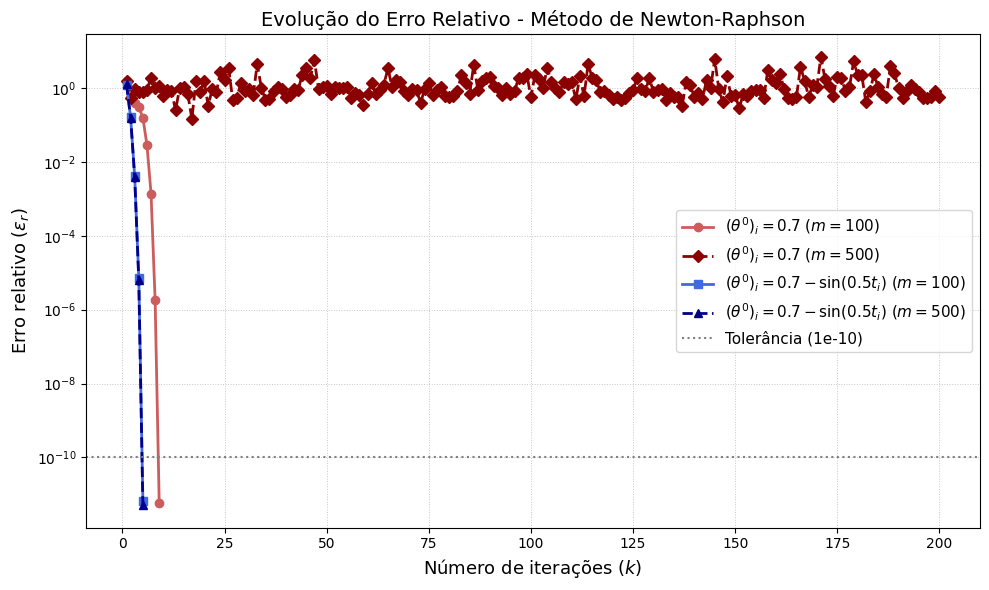

In [9]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

fig, ax = plt.subplots(figsize=(10, 6))

# Plotando Caso A (Tons de Vermelho)
# m=100 (linha contínua, bolinhas, vermelho mais claro)
ax.semilogy(range(1, iter_a_100 + 1), erros_a_100, marker="o", linestyle="-", linewidth=2, markersize=6,
            color="indianred", label=r"$(\theta^0)_i = 0.7$ ($m=100$)")
# m=500 (linha tracejada, losangos, vermelho mais escuro)
ax.semilogy(range(1, iter_a_500 + 1), erros_a_500, marker="D", linestyle="--", linewidth=2, markersize=6,
            color="darkred", label=r"$(\theta^0)_i = 0.7$ ($m=500$)")

# Plotando Caso B (Tons de Azul)
# m=100 (linha contínua, quadrados, azul claro)
ax.semilogy(range(1, iter_b_100 + 1), erros_b_100, marker="s", linestyle="-", linewidth=2, markersize=6,
            color="royalblue", label=r"$(\theta^0)_i = 0.7 - \sin(0.5t_i)$ ($m=100$)")
# m=500 (linha tracejada, triângulos, azul escuro)
ax.semilogy(range(1, iter_b_500 + 1), erros_b_500, marker="^", linestyle="--", linewidth=2, markersize=6,
            color="darkblue", label=r"$(\theta^0)_i = 0.7 - \sin(0.5t_i)$ ($m=500$)")

# Linha de tolerância
ax.axhline(tol, color="gray", linestyle=":", linewidth=1.5, label=f"Tolerância ({tol})")

# Formatação dos Eixos e Títulos
ax.set_xlabel("Número de iterações ($k$)", fontsize=13)
ax.set_ylabel(r"Erro relativo ($\epsilon_r$)", fontsize=13)
ax.set_title("Evolução do Erro Relativo - Método de Newton-Raphson", fontsize=14)

# Ajustes refinados de escala e ticks
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.yaxis.set_major_formatter(ticker.LogFormatterMathtext())

# Grid e Legenda
ax.grid(True, which="both", linestyle=":", linewidth=0.7, alpha=0.7)
ax.legend(fontsize=11, loc="best")

plt.tight_layout()
plt.show()

### Animação do Movimento do Pêndulo

Abaixo, utilizaremos a solução numérica mais precisa que encontramos (Caso b com $m=500$) para animar o percurso do pêndulo no tempo. Extraímos as posições geométricas através das relações trigonométricas:
$$ x(t) = L \sin(\theta(t)) $$
$$ y(t) = -L \cos(\theta(t)) $$

In [10]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Adicionamos os nós de contorno no vetor para visualizar os extremos do tempo
sol = sol_b_500
n = len(sol) + 2

theta_full = np.zeros(n)
theta_full[0] = alpha_val
theta_full[1:-1] = sol
theta_full[-1] = beta_val

# Vetor tempo completo
t_full = np.linspace(0, T_val, n)

# O comprimento foi estipulado no roteiro
L = 1.0
# Conversão de coordenadas polares para cartesianas
x_coord = L * np.sin(theta_full)
y_coord = -L * np.cos(theta_full)

fig, ax = plt.subplots(figsize=(6, 6))
ax.set_aspect('equal')
ax.set_xlim(-1.2*L, 1.2*L)
ax.set_ylim(-1.2*L, 0.2*L)
ax.grid(True, linestyle='--', alpha=0.6)
ax.set_title("Movimento do Pêndulo Simples Numérico", fontsize=14)
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")

# Haste e peso do pêndulo
line, = ax.plot([], [], 'o-',
                lw=3,
                markersize=15,
                color='gray',
                markerfacecolor='orange',
                markeredgecolor='gray')
# Texto descritivo na tela
time_text = ax.text(0.05, 0.92, '', transform=ax.transAxes, fontsize=12)

def init():
    line.set_data([], [])
    time_text.set_text('')
    return line, time_text

# Realizamos uma subamostragem (ex: 120 frames) para uma animação fluida no HTML
num_frames = 120
frames_idx = np.linspace(0, len(t_full)-1, num_frames).astype(int)

def animate(i):
    idx = frames_idx[i]
    thisx = [0, x_coord[idx]]
    thisy = [0, y_coord[idx]]
    line.set_data(thisx, thisy)
    time_text.set_text(f'Tempo = {t_full[idx]:.2f} s')
    return line, time_text

intervalo_ms = (T_val / num_frames) * 1000

ani = FuncAnimation(fig, animate, frames=num_frames, init_func=init, blit=True, interval=intervalo_ms)

plt.close(fig) # Fecha o estático auxiliar vazio
HTML(ani.to_jshtml())

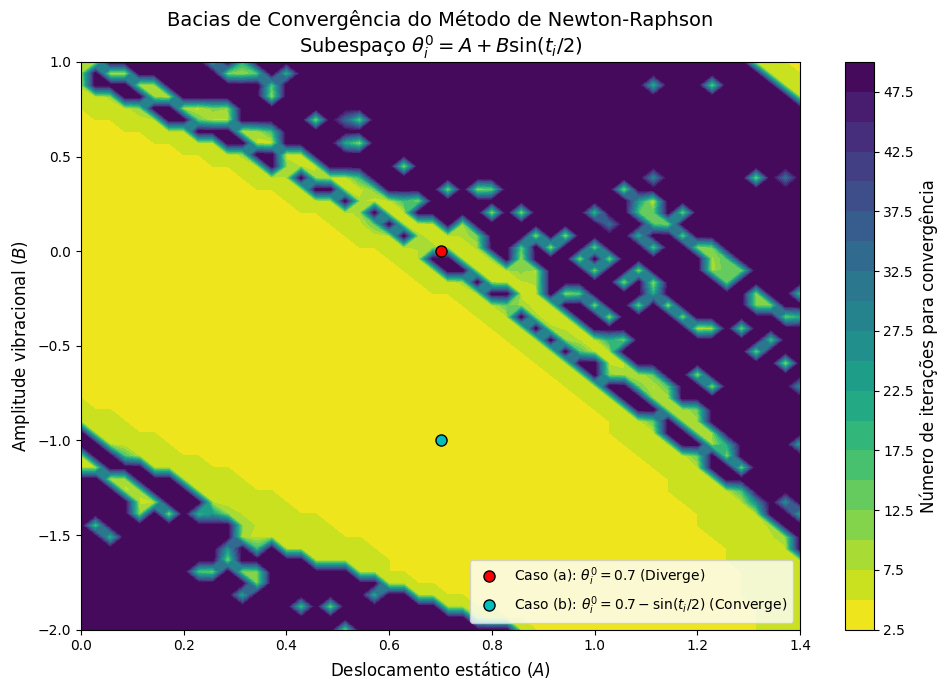

In [11]:
# Parâmetros para construção do subespaço de condições iniciais
m_bacia = 100 # Discretização reduzida para otimização da varredura na malha (evita elevado custo computacional)
T_val = 2 * np.pi
alpha_val = 0.7
beta_val = 0.7
tol_bacia = 1e-5
max_iter_bacia = 50

# Compilação do sistema de equações e obtenção do vetor de discretização temporal
F_eval, J_eval, h_val = substituir_sistema_pendulo(m_bacia, T_val, alpha_val, beta_val)
t_i = np.linspace(h_val, T_val - h_val, m_bacia)

# Construção do espaço de parâmetros bidimensional (A, B)
A_vals = np.linspace(0.0, 1.4, 50)
B_vals = np.linspace(-2.0, 1.0, 50)
A_grid, B_grid = np.meshgrid(A_vals, B_vals)
iteracoes_grid = np.zeros(A_grid.shape)

# Varredura do subespaço matricial e avaliação estrita da convergência local
for i in range(A_grid.shape[0]):
    for j in range(A_grid.shape[1]):
        theta0 = A_grid[i, j] + B_grid[i, j] * np.sin(t_i / 2)
        try:
            sol, iters, res, erros = metodo_newton(F_eval, J_eval, theta0, tol=tol_bacia, max_iter=max_iter_bacia)
            # Regiões que atingem o critério de parada com estabilidade e precisão
            if len(erros) > 0 and erros[-1] < tol_bacia and iters < max_iter_bacia:
                iteracoes_grid[i, j] = iters
            else:
                iteracoes_grid[i, j] = max_iter_bacia
        except Exception:
            # Captura de instabilidades numéricas e violação de domínio (ex: pivôs nulos no TDMA)
            iteracoes_grid[i, j] = max_iter_bacia

# Representação visual das bacias de convergência topológicas
fig, ax = plt.subplots(figsize=(10, 7))
cp = ax.contourf(A_grid, B_grid, iteracoes_grid, levels=20, cmap='viridis_r')
cbar = fig.colorbar(cp, ax=ax)
cbar.set_label('Número de iterações para convergência', fontsize=12)

# Mapeamento rigoroso das aproximações estáticas e variáveis do problema original
ax.plot(0.7, 0.0, 'ro', markersize=8, markeredgecolor='black', label='Caso (a): $\\theta^0_i = 0.7$ (Diverge)')
ax.plot(0.7, -1.0, 'co', markersize=8, markeredgecolor='black', label='Caso (b): $\\theta^0_i = 0.7 - \\sin(t_i/2)$ (Converge)')

ax.set_xlabel('Deslocamento estático ($A$)', fontsize=12)
ax.set_ylabel('Amplitude vibracional ($B$)', fontsize=12)
ax.set_title('Bacias de Convergência do Método de Newton-Raphson\nSubespaço $\\theta^0_i = A + B \\sin(t_i/2)$', fontsize=14)
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

## 4. Sensibilidade da Solução (Terra vs. Mercúrio)

Nesta seção, analisamos a sensibilidade da solução às variações dos parâmetros físicos do pêndulo. O roteiro sugere especificamente investigar o comportamento do sistema caso ele estivesse sujeito à gravidade de **Mercúrio** ($g \approx 3.7 \, \text{m/s}^2$).

A variação nos parâmetros ($\alpha, \beta, L, g$) afeta diretamente a matriz Jacobiana e o vetor de resíduos do método numérico:
- O comprimento $L$ e a gravidade $g$ definem a frequência natural de oscilação do sistema. Em Mercúrio, com menor $g$, a força restauradora é mais fraca. 
- Para satisfazer os mesmos valores de contorno ($\alpha = \beta = 0.7$) no mesmo tempo $T = 2\pi$, o pêndulo em Mercúrio precisará descrever uma trajetória com dinâmica diferente para compensar a gravidade reduzida. Como o período natural aumenta, a solução pode precisar atingir amplitudes diferentes.

Abaixo, calculamos a solução em Mercúrio e geramos uma animação comparativa para observar o movimento lado a lado com a Terra.

In [12]:
# Parâmetros globais
T_val = 2 * np.pi
alpha_val = 0.7
beta_val = 0.7
m = 500
tol = 1e-10
max_iter = 200

# Solução para a Terra (g = 9.8 m/s²)
F_eval_terra, J_eval_terra, h_val = substituir_sistema_pendulo(m, T_val, alpha_val, beta_val, g_val=9.8, L_val=1.0)
t_i = np.linspace(h_val, T_val - h_val, m)
theta0_terra = alpha_val - np.sin(t_i / 2)
sol_terra, iters_terra, _, _ = metodo_newton(F_eval_terra, J_eval_terra, theta0_terra, tol=tol, max_iter=max_iter)

# Solução para Mercúrio (g = 3.7 m/s²)
F_eval_merc, J_eval_merc, _ = substituir_sistema_pendulo(m, T_val, alpha_val, beta_val, g_val=3.7, L_val=1.0)
theta0_merc = alpha_val - np.sin(t_i / 2)
sol_merc, iters_merc, _, _ = metodo_newton(F_eval_merc, J_eval_merc, theta0_merc, tol=tol, max_iter=max_iter)

print(f"Terra resolvida em {iters_terra} iterações. Mercúrio resolvido em {iters_merc} iterações.")

# Preenchimento dos vetores completos de tempo e ângulo (incluindo condições de contorno)
theta_full_terra = np.zeros(m+2)
theta_full_terra[0], theta_full_terra[1:-1], theta_full_terra[-1] = alpha_val, sol_terra, beta_val

theta_full_merc = np.zeros(m+2)
theta_full_merc[0], theta_full_merc[1:-1], theta_full_merc[-1] = alpha_val, sol_merc, beta_val

t_full = np.linspace(0, T_val, m+2)
L = 1.0

# Coordenadas cartesianas
x_terra = L * np.sin(theta_full_terra)
y_terra = -L * np.cos(theta_full_terra)

x_merc = L * np.sin(theta_full_merc)
y_merc = -L * np.cos(theta_full_merc)

# Configuração da Animação Lado a Lado
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
for ax, title in zip([ax1, ax2], ["Terra ($g=9.8$ m/s²)", "Mercúrio ($g=3.7$ m/s²)"]):
    ax.set_aspect('equal')
    ax.set_xlim(-1.2*L, 1.2*L)
    ax.set_ylim(-1.2*L, 0.2*L)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.set_title(title, fontsize=12)
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")

line_terra, = ax1.plot([], [], 'o-', lw=3, markersize=12, color='gray', markerfacecolor='royalblue')
line_merc, = ax2.plot([], [], 'o-', lw=3, markersize=12, color='gray', markerfacecolor='firebrick')
time_text = ax1.text(0.05, 0.92, '', transform=ax1.transAxes, fontsize=10)

def init():
    line_terra.set_data([], [])
    line_merc.set_data([], [])
    time_text.set_text('')
    return line_terra, line_merc, time_text

num_frames = 120
frames_idx = np.linspace(0, len(t_full)-1, num_frames).astype(int)

def animate(i):
    idx = frames_idx[i]
    line_terra.set_data([0, x_terra[idx]], [0, y_terra[idx]])
    line_merc.set_data([0, x_merc[idx]], [0, y_merc[idx]])
    time_text.set_text(f'Tempo = {t_full[idx]:.2f} s')
    return line_terra, line_merc, time_text

intervalo_ms = (T_val / num_frames) * 1000
ani = FuncAnimation(fig, animate, frames=num_frames, init_func=init, blit=True, interval=intervalo_ms)
plt.close(fig)
HTML(ani.to_jshtml())

Terra resolvida em 5 iterações. Mercúrio resolvido em 5 iterações.


## 5. Comparação: Solução Não Linear vs. Linearização

O modelo clássico introduzido nos cursos iniciais de física e equações diferenciais adota a aproximação de pequenos ângulos. A validade dessa aproximação baseia-se na série de Taylor do seno:
$$ \sin(\theta) = \theta - \frac{\theta^3}{3!} + \frac{\theta^5}{5!} - \dots $$

Para ângulos suficientemente pequenos, os termos de ordem superior são irrelevantes e assumimos $\sin(\theta) \approx \theta$. Isso transforma a equação original não linear em uma Equação Diferencial Ordinária (EDO) linear de segunda ordem, com coeficientes constantes:
$$ \theta''(t) + \omega^2 \theta(t) = 0 \quad \text{onde} \quad \omega = \sqrt{\frac{g}{L}} $$

**Dedução da Solução Analítica (Problema de Valor de Contorno):**
A solução geral para essa EDO é uma combinação linear de senos e cossenos (oscilador harmônico simples):
$$ \theta(t) = A \cos(\omega t) + B \sin(\omega t) $$

Para encontrar as constantes $A$ e $B$, aplicamos as condições de contorno $\theta(0) = \alpha$ e $\theta(T) = \beta$:
1. **Para $t = 0$:**
   $$ \theta(0) = A \cos(0) + B \sin(0) = \alpha \implies A = \alpha $$
2. **Para $t = T$:**
   $$ \theta(T) = \alpha \cos(\omega T) + B \sin(\omega T) = \beta $$
   Isolando a constante $B$:
   $$ B = \frac{\beta - \alpha \cos(\omega T)}{\sin(\omega T)} $$

É exatamente esta expressão analítica fechada que foi implementada na função `solucao_linearizada` na célula abaixo. Note também uma particularidade importante que precisou ser tratada no código: se $\sin(\omega T) = 0$, teremos uma divisão por zero para achar $B$. Fisicamente, isso ocorre quando o tempo $T$ é um múltiplo exato do meio-período natural do pêndulo. Nesses casos de "ressonância", o problema de valor de contorno torna-se mal condicionado (as condições de contorno podem não possuir solução única ou sequer possuir solução), o que requer um tratamento de exceção computacional.

**Consequências observadas em grandes amplitudes:**
À medida que a amplitude inicial aumenta, a força de restauração modelada pela equação linear ($\sim \theta$) torna-se significativamente maior do que a força real atuante no pêndulo não linear ($\sim \sin(\theta)$). 
1. **Frequência de oscilação:** O modelo linearizado tem um período constante $T_0 = 2\pi\sqrt{L/g}$, estritamente independente da amplitude. Na realidade (não linear), o período cresce com a amplitude (o pêndulo "atrasa"), fazendo as duas soluções saírem de fase rapidamente.
2. **Divergência Acumulada:** O erro não apenas surge nas amplitudes extremas, mas acumula-se de forma gritante com o passar do tempo.

Abaixo, calculamos analiticamente essa curva linearizada e a comparamos diretamente com a solução não linear obtida via Newton-Raphson. Testamos um cenário de pequenos ângulos (onde há uma ótima concordância) e um cenário de maiores amplitudes ($\alpha = 1.0$), onde a falha do modelo e a defasagem se tornam evidentes na dinâmica do movimento.

Resolvido em 4 iterações.
Resolvido em 200 iterações.


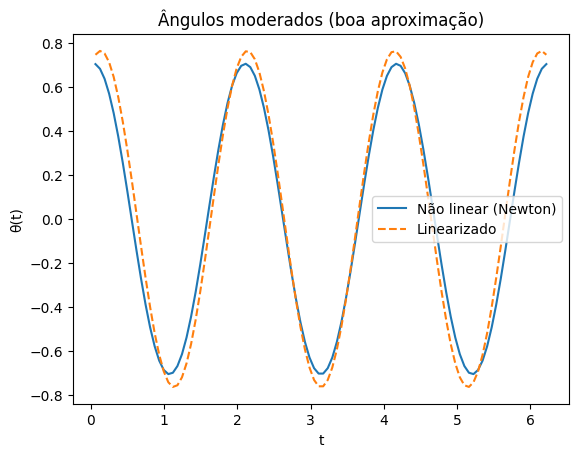

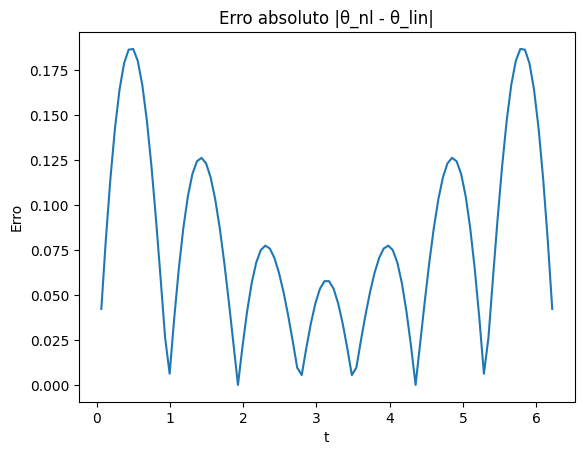

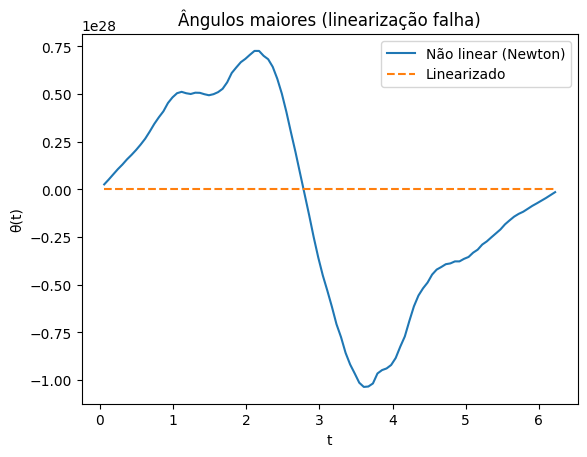

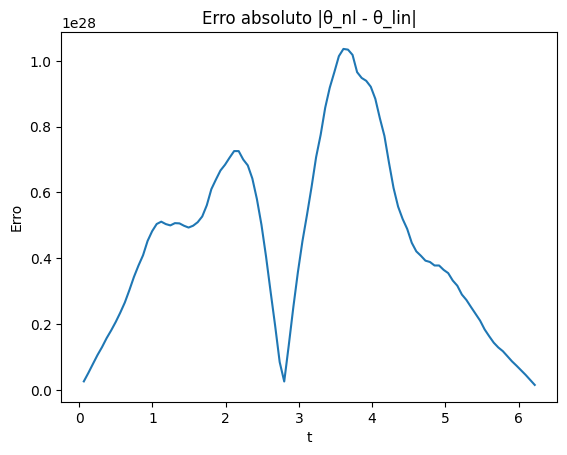

In [36]:
def solucao_linearizada(t_i, T, alpha, beta, g=9.8, L=1.0):
    """ 
    a função recebe parâmetros do sistema pendular (idênticos aos inseridos na função 
    'compilar_sistema_pendulo') e retorna um vetor de aproximações de theta para os 
    valores de t_i fornecidos, utilizando a aproximação de sin(theta) = theta; 
    """

    omega = np.sqrt(g / L)
    A = alpha
    denom = np.sin(omega * T)

    if np.abs(denom) < 1e-12:
        raise ValueError("sin(omega*T) próximo de theta; problema mal condicionado.")

    B = (beta - alpha * np.cos(omega * T)) / denom

    return (A * np.cos(omega * t_i) + B * np.sin(omega * t_i))


def resolver_caso(alpha_val, beta_val, m):
    """ 
    para dados valores de alpha, beta, e m, a função calcula as aproximações para
    os 2 casos desejados: linearização e Newton-Raphson (cujo chute inicial é o 
    resultado da própria linearização)
    """
    T_val = 2 * np.pi

    F_eval, J_eval, h_val = substituir_sistema_pendulo(
        m=m, T_val=T_val, alpha_val=alpha_val, beta_val=beta_val
    )

    t_i = np.linspace(h_val, T_val - h_val, m)

    # solução linearizada
    theta0 = solucao_linearizada(t_i, T_val, alpha_val, beta_val)
    # aplicação do método de newton (chute inicial = theta0)
    sol, iteracoes, res, _ = metodo_newton(F_eval, J_eval, theta0, tol=1e-5)

    print(f"Resolvido em {iteracoes} iterações.")

    return t_i, sol, theta0

# Abaixo serão exibidas as diferenças entre ambos os métodos de aproximação

import matplotlib.pyplot as plt

def plot_diferenca_e_erro(t_i, sol, theta_lin, titulo):
    plt.plot(t_i, sol, label="Não linear (Newton)")
    plt.plot(t_i, theta_lin, '--', label="Linearizado")
    plt.legend()
    plt.xlabel("t")
    plt.ylabel("θ(t)")
    plt.title(titulo)
    plt.show()

    plt.plot(t_i, np.abs(sol - theta_lin))
    plt.title("Erro absoluto |θ_nl - θ_lin|")
    plt.xlabel("t")
    plt.ylabel("Erro")
    plt.show()

# Caso 1: pequeno ângulo
t_i1, sol_1, theta_lin_1 = resolver_caso(0.7, 0.7, m=100)
# Caso 2: ângulo maior
t_i2, sol_2, theta_lin_2 = resolver_caso(1.1, 1.1, m=100)

plot_diferenca_e_erro(t_i1, sol_1, theta_lin_1, "Ângulos moderados (boa aproximação)")
plot_diferenca_e_erro(t_i2, sol_2, theta_lin_2, "Ângulos maiores (linearização falha)")